## TTB948 Engineering Analysis and Optimisation

Part B: Optimisation

Session 2: Regression

Sectian b: proper regression


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


## Revision History

| Aspect | Value |
| ------ | ------ |
| Owner | Thomas Steffen |
| Location | Google colab / drive |
| Confidentiality | Public |

| Date | Update |
| ---- | ------ |
| 2026-11-10 | spawn |
| 2026-11-12 | tweaks |

In [ ]:
from datetime import datetime
str(datetime.today())

'2026-11-11 10:54:17.837902'

## Define our ground truth

> Add blockquote



We pick $$(u-0.5)^2+1=u^2-u+1.25$$


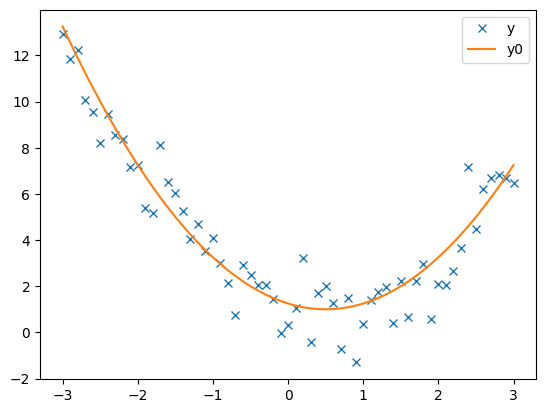

In [ ]:
def real(u):
  return (u-0.5)**2+1

u = np.arange(-3,+3.1,0.1)
y0 = real(u)
y = y0 + 1.0*np.random.randn(np.size(u))

plt.plot(u, y, 'x', label='y')
plt.plot(u, y0, label='y0')
plt.legend()

## USing Derivatives

* Calculate the slope
* Calculate the slope change
* Find the parameters

In [ ]:
dy = y[1:]-y[:-1]
ddy = dy[1:]-dy[:-1]

c2 = np.mean(ddy)/2
c1 = np.mean(dy)
c0 = y[(np.size(y)-1)//2]

print(c2,c1,c0)

0.0074251161359346765 -0.10780945667630154 0.30173874013147073


# Using a Square Monomial

1.1780404950349386


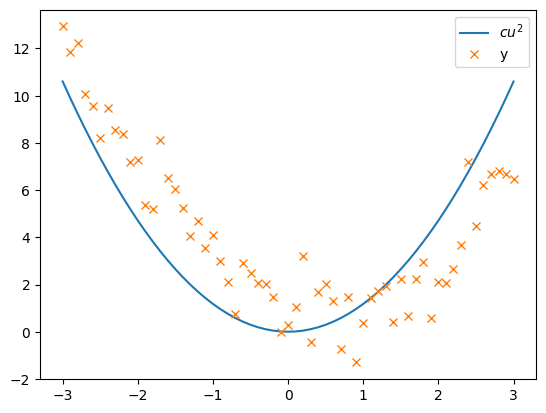

In [ ]:
def fb(u):
  return u**2
b = fb(u)
up = np.arange(-3, 3.1, 0.1)

c = np.dot(y,b)/np.dot(b,b)
print(c)

plt.plot(up, c*fb(up), label='$cu^2$')
plt.plot(u, y, 'x', label='y')
plt.legend()

## Three Monomials

We can use the pseudo inverse!


[ 1.13389172 -1.01368711  0.97476123]


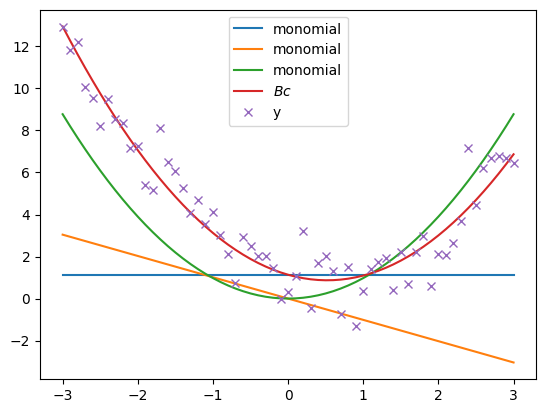

In [ ]:
b0 = u**0
b1 = u**1
b2 = u**2
B = np.column_stack((b0, b1, b2))

Binv = np.linalg.pinv(B)
c = np.dot(Binv,y)
print(c)

plt.plot(up, B*c, label='monomial')
plt.plot(up, np.dot(B,c), label='$Bc$')
plt.plot(u, y, 'x', label='y')
plt.legend()

## And Now the Lazy Way

Use Pandas

In [ ]:
import pandas as pd
df = pd.DataFrame({
    'u': u,
    'y': y,
})
print(df)

      u          y
0  -3.0  12.932764
1  -2.9  11.844010
2  -2.8  12.231221
3  -2.7  10.080126
4  -2.6   9.560334
..  ...        ...
56  2.6   6.203554
57  2.7   6.675983
58  2.8   6.802152
59  2.9   6.676786
60  3.0   6.464196

[61 rows x 2 columns]


## Linear Regression (R style)

Uses statsmodels

In [ ]:
import statsmodels.formula.api as smf
model = smf.ols("y ~ u + I(u**2)", data=df)
results = model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.905
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     277.2
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           2.06e-30
Time:                        10:54:25   Log-Likelihood:                -89.373
No. Observations:                  61   AIC:                             184.7
Df Residuals:                      58   BIC:                             191.1
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.1339      0.206      5.496      0.0

## Plot The Result



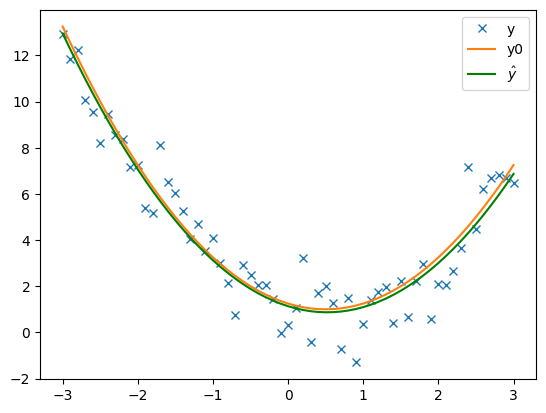

In [ ]:
yhat = results.predict(df)
plt.plot(u, y, 'x', label='y')
plt.plot(u, y0, label='y0')
plt.plot(u, yhat, label="$\\hat{y}$", color='green')
plt.legend()
plt.show()

## Minimum

Solve the derivate
$$2 c_2 u + c_1 = 0$$
for $u^*$.

In [ ]:
c = results.params
c0 = c["Intercept"]
c1 = c["u"]
c2 = c["I(u ** 2)"]

us = -c1/2/c2
us

np.float64(0.519966878547782)

## Or call an optimisation

In [ ]:
import scipy.optimize as opt

def f(u):
  return c0 + c1*u + c2*u**2

uopt = opt.minimize(f,[0])
print(uopt)
print(uopt.x)


  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 0.8703498562904562
        x: [ 5.200e-01]
      nit: 1
      jac: [ 7.451e-09]
 hess_inv: [[1]]
     nfev: 6
     njev: 3
[0.51996688]


## Review

Now we are talking!

The position is remarkably accurate, much better than going directly with the data.

The value of the optimum is just slightly off, within expectations.